# Predicting Email Reply Likelihood
Applied Math for Deep Learning - Group Project

In [ ]:
# Dataset: Enron email corpus (Hugging Face), https://huggingface.co/datasets/corbt/enron-emails
# Business problem: predict, before sending, whether an outbound email is likely to get a reply.
# This helps prioritize follow-ups and flag emails that may need rewriting before they go out.

## Get the Data
We use the Enron email dataset from Hugging Face.

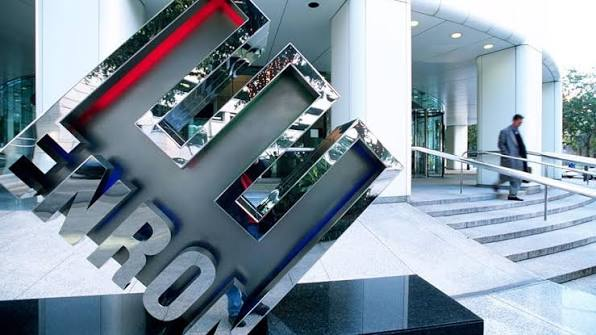

In [ ]:
!pip install datasets -q

from datasets import load_dataset
import pandas as pd
import numpy as np
import re

ds = load_dataset("corbt/enron-emails", split="train")
df = ds.to_pandas()

print(df.columns.tolist())
print(df.head(3))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/581 [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  185MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  167MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  141MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/517401 [00:00<?, ? examples/s]

['message_id', 'subject', 'from', 'to', 'cc', 'bcc', 'date', 'body', 'file_name']
                                      message_id   subject  \
0  <18782981.1075855378110.JavaMail.evans@thyme>             
1  <15464986.1075855378456.JavaMail.evans@thyme>       Re:   
2  <24216240.1075855687451.JavaMail.evans@thyme>  Re: test   

                      from                         to  cc bcc  \
0  phillip.allen@enron.com     [tim.belden@enron.com]  []  []   
1  phillip.allen@enron.com  [john.lavorato@enron.com]  []  []   
2  phillip.allen@enron.com   [leah.arsdall@enron.com]  []  []   

                       date  \
0 2001-05-14 23:39:00+00:00   
1 2001-05-04 20:51:00+00:00   
2 2000-10-18 10:00:00+00:00   

                                                body                file_name  
0                          Here is our forecast\n\n     allen-p/_sent_mail/1.  
1  Traveling to have a business meeting takes the...   allen-p/_sent_mail/10.  
2                     test successful.  way

In [ ]:
df_full = df.rename(columns={
    "message_id": "Message-ID", "from": "From", "to": "To",
    "subject": "Subject", "date": "Date", "body": "Body",
})

# 50,000 emails
df_sample = df_full.sample(n=50000, random_state=42).reset_index(drop=True)
print(df_sample.shape)

(50000, 9)


## Labeling
This dataset has no reply-thread field, so we label an email as "got a reply" (1)
by matching subject + recipient + a 30 day window against the full corpus.

In [ ]:
def to_list(x):
    if x is None:
        return []
    try:
        return list(x)
    except TypeError:
        return []


def is_nonempty_list(x):
    if x is None:
        return False
    try:
        return len(x) > 0
    except TypeError:
        return False


def strip_re(subject):
    return re.sub(r"^(re:\s*)+", "", str(subject), flags=re.IGNORECASE).strip()

In [ ]:
#Touhid do this please
def filter_outbound(df):
    mask = (
        df["From"].notna()
        & df["To"].apply(is_nonempty_list)
        & ~df["Subject"].fillna("").str.contains(
            "Out of Office|Undeliverable|Delivery Status", case=False, na=False
        )
        & (df["Body"].fillna("").str.split().str.len() >= 10)
    )
    return df[mask].reset_index(drop=True)

In [ ]:

def label_against_full_corpus(outbound_df, full_df):
    full_df = full_df.copy()
    full_df["stripped_subject"] = full_df["Subject"].apply(strip_re)

    subject_groups = {}
    for subj, group in full_df.groupby("stripped_subject"):
        subject_groups[subj] = list(zip(group["From"], group["Date"]))

    labels = []
    for row in outbound_df.itertuples(index=False):
        row = row._asdict()
        recipients = set(to_list(row["To"]))
        subj_key = strip_re(row["Subject"])
        row_date = row["Date"]

        found = False
        if recipients and subj_key in subject_groups:
            for cand_from, cand_date in subject_groups[subj_key]:
                if (cand_from in recipients
                        and cand_date > row_date
                        and cand_date <= row_date + pd.Timedelta(days=30)):
                    found = True
                    break
        labels.append(int(found))

    result = outbound_df.copy()
    result["label"] = labels
    return result

In [ ]:
outbound = filter_outbound(df_sample)
print(f"outbound rows after filtering: {len(outbound)} (out of {len(df_sample)} sampled)")

result = label_against_full_corpus(outbound, df_full)

# check the label balance
print(result["label"].value_counts(normalize=True))

outbound rows after filtering: 47392 (out of 50000 sampled)
label
0    0.837715
1    0.162285
Name: proportion, dtype: float64


## Data Analysis: What's Associated With Getting a Reply
A quick look at whether email length or time of day relates to getting a reply,
using the labeled (but not yet cleaned) data.

In [ ]:
# quick look at what's associated with getting a reply
result["word_count"] = result["Body"].str.split().str.len()
result["hour"] = pd.to_datetime(result["Date"]).dt.hour

print(result.groupby("label")["word_count"].mean())
print("correlation between email length and getting a reply:", result["word_count"].corr(result["label"]))

label
0    287.300370
1    247.282148
Name: word_count, dtype: float64
correlation between email length and getting a reply: -0.01648249752215654


/tmp/ipykernel_1896/3439680001.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  reply_rate_by_length = result.groupby(pd.cut(result["word_count"], bins=[0, 25, 50, 100, 200, 1000]))["label"].mean()


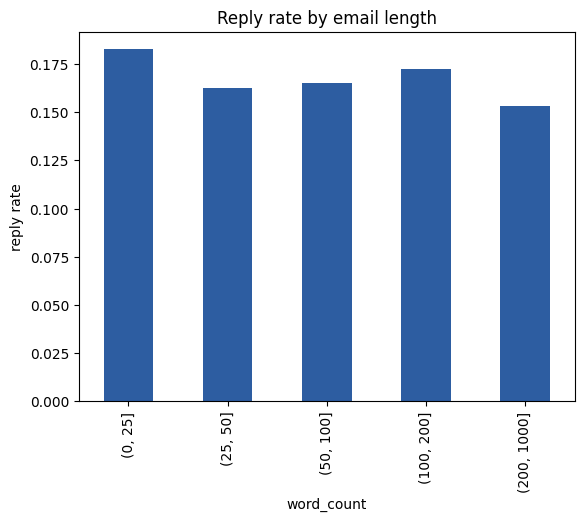

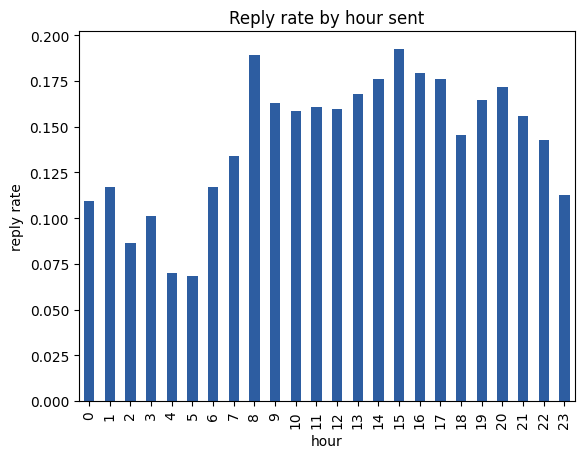

In [ ]:
import matplotlib.pyplot as plt

reply_rate_by_length = result.groupby(pd.cut(result["word_count"], bins=[0, 25, 50, 100, 200, 1000]))["label"].mean()
reply_rate_by_length.plot(kind="bar", color="#2D5DA1")
plt.ylabel("reply rate")
plt.title("Reply rate by email length")
plt.show()

reply_rate_by_hour = result.groupby("hour")["label"].mean()
reply_rate_by_hour.plot(kind="bar", color="#2D5DA1")
plt.ylabel("reply rate")
plt.title("Reply rate by hour sent")
plt.show()

### Validate a Sample by Hand
Automated labels can be wrong, so before trusting them we check a random sample
manually and calculate agreement.
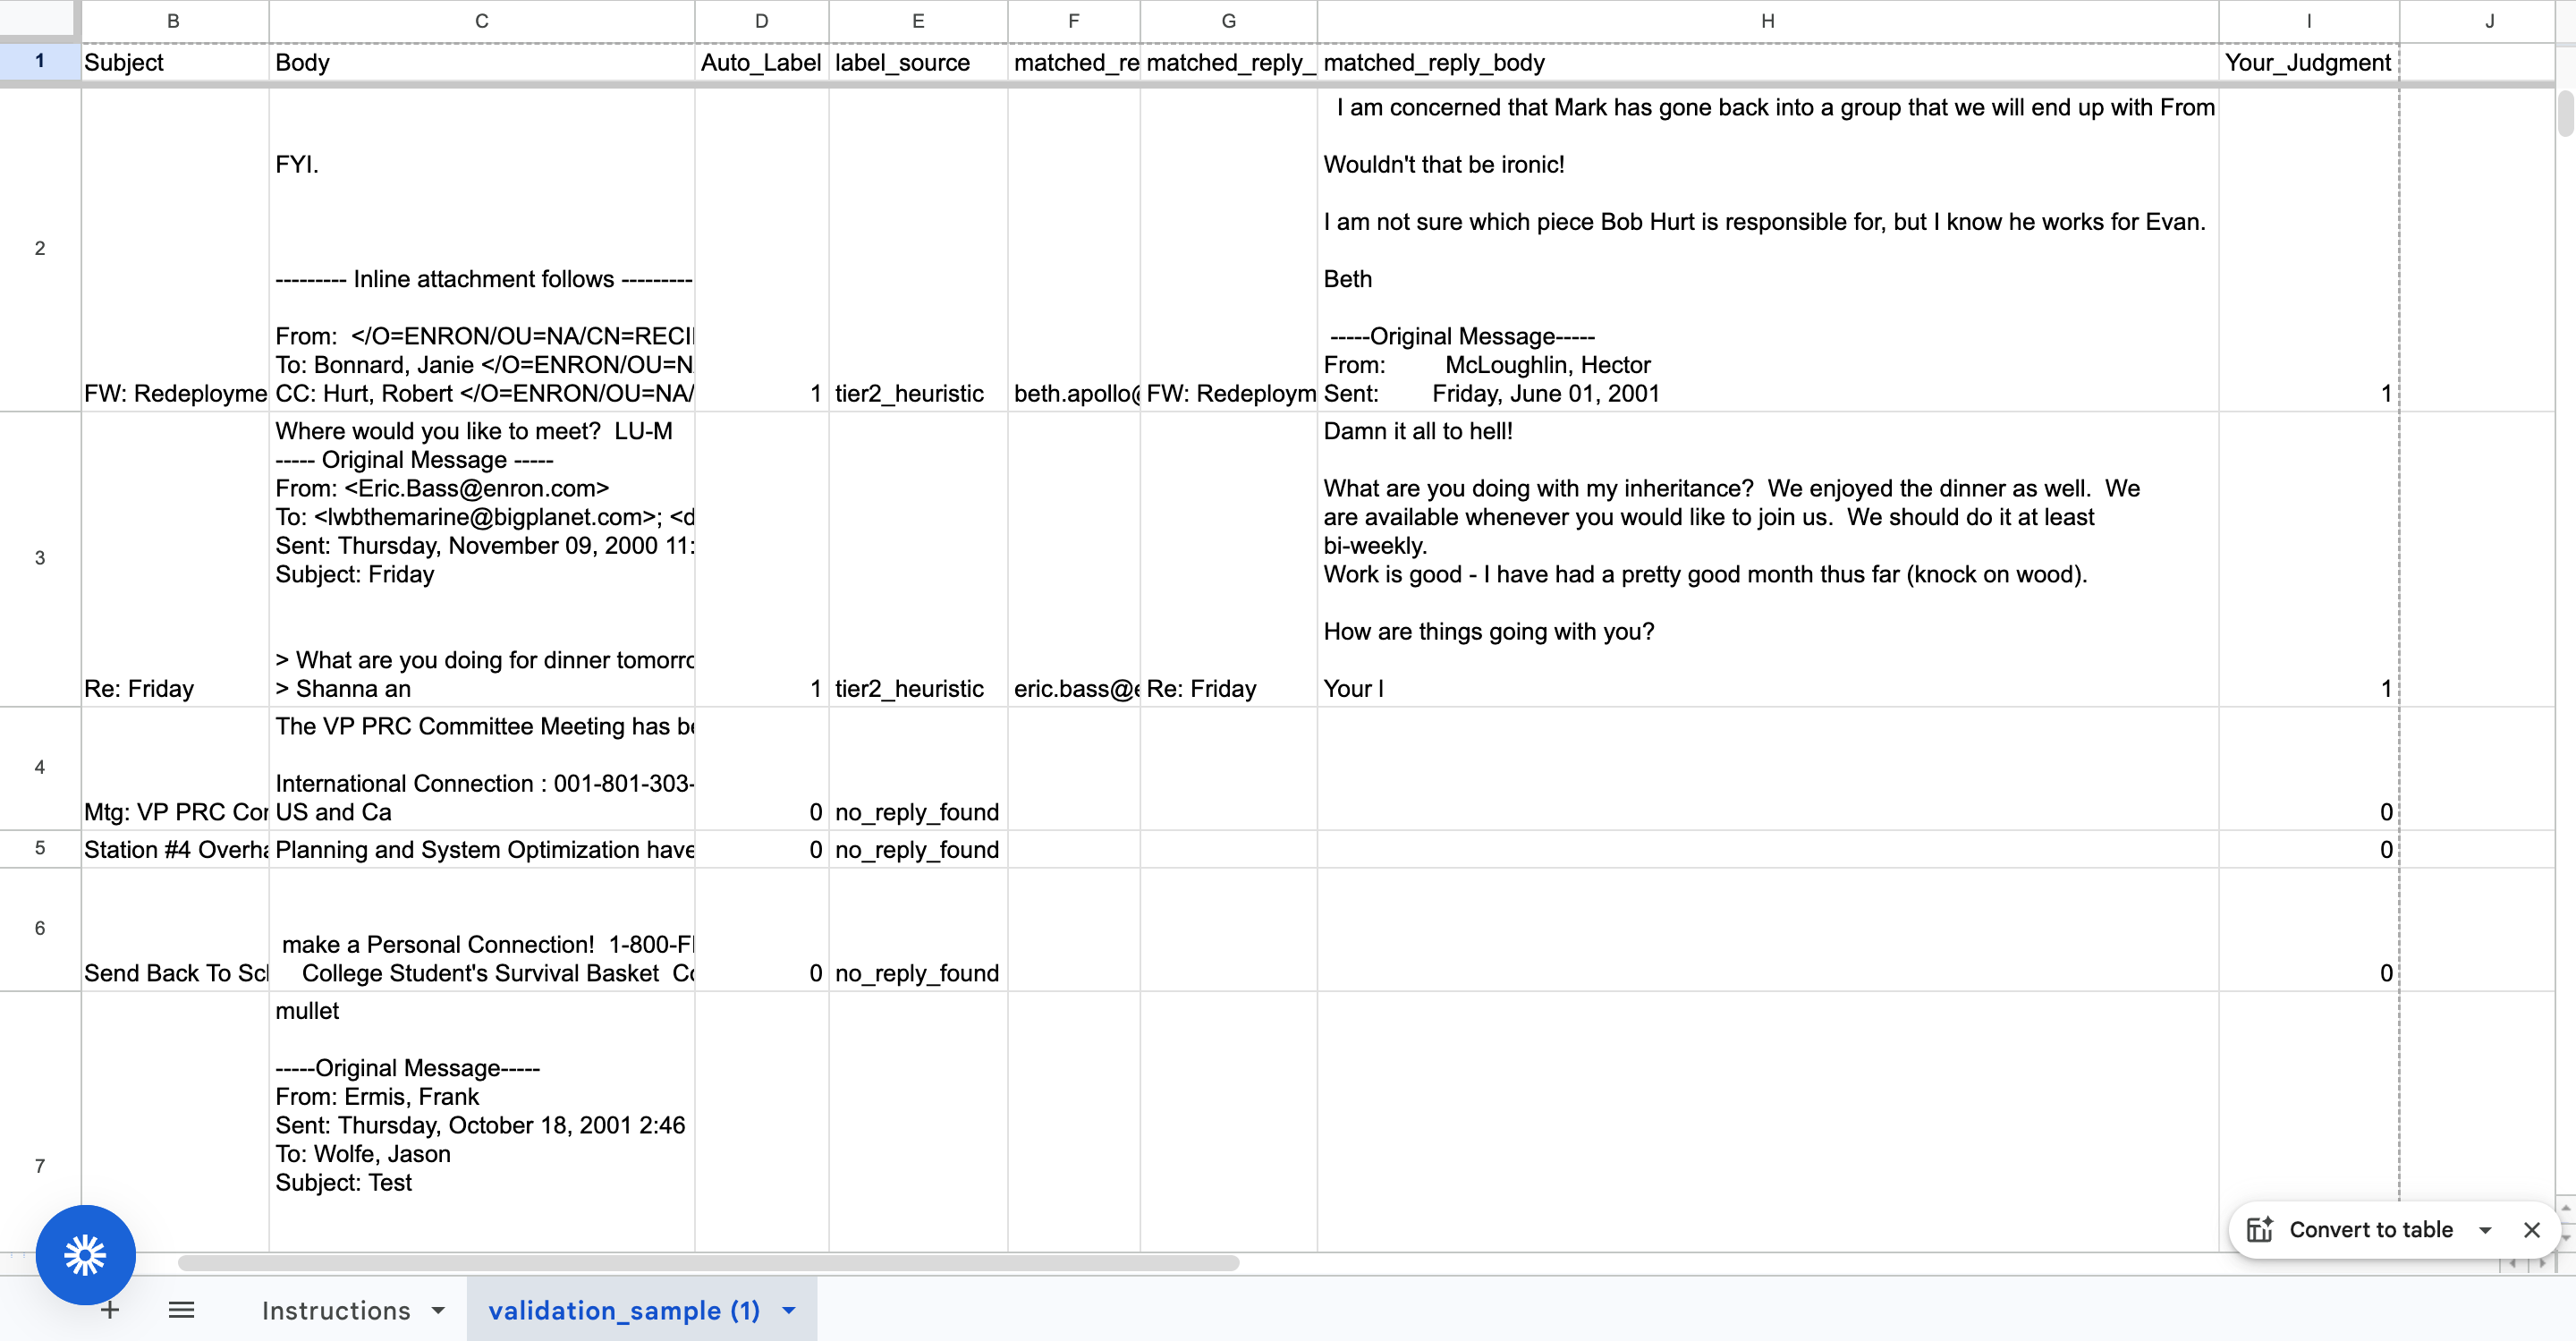

In [ ]:
def export_validation_sample(labeled_df, n=150, seed=42):
    pos = labeled_df[labeled_df["label"] == 1].sample(
        n=min(n // 2, (labeled_df["label"] == 1).sum()), random_state=seed)
    neg = labeled_df[labeled_df["label"] == 0].sample(
        n=min(n // 2, (labeled_df["label"] == 0).sum()), random_state=seed)
    sample = pd.concat([pos, neg]).sample(frac=1, random_state=seed).reset_index(drop=True)

    export = sample[["Message-ID", "Subject", "Body", "label"]].copy()
    export["Body"] = export["Body"].str.slice(0, 300)
    export["Your_Judgment"] = ""
    export = export.rename(columns={"label": "Auto_Label"})

    export.to_csv("validation_sample.csv", index=False)
    print(f"exported {len(export)} rows to validation_sample.csv")
    return export


validation_sample = export_validation_sample(result, n=150)
validation_sample.head()

exported 150 rows to validation_sample.csv


,Message-ID,Subject,Body,Auto_Label,Your_Judgment
0,<15598028.1075844731574.JavaMail.evans@thyme>,Hawaii Presentation,----- Forwarded by Mark Taylor/HOU/ECT on 04/1...,1,
1,<16713087.1075839938650.JavaMail.evans@thyme>,RE: FW: Disabling EST Accounts,It is in the best interest of the Estate to ke...,1,
2,<24618634.1075849429188.JavaMail.evans@thyme>,Re: Outlook Migration and E-Mail retention sch...,A couple of points to clarify - You'll still h...,0,
3,<24542429.1075858240927.JavaMail.evans@thyme>,Re: FW: Wasss Uuuuuup STG?,"so it last week, pretty funny. It looks like ...",0,
4,<14011819.1075841054152.JavaMail.evans@thyme>,Start Date: 4/16/01; HourAhead hour: 12; <COD...,Start Date: 4/16/01; HourAhead hour: 12; No a...,0,


### Lock In the Final Labeled Dataset

In [ ]:
final_dataset = result[["Message-ID", "Subject", "Body", "label"]].copy()

print(f"final labeled dataset: {len(final_dataset)} rows")
print(final_dataset["label"].value_counts(normalize=True))

final_dataset.to_csv("labeled_enron_emails_final.csv", index=False)

final labeled dataset: 47392 rows
label
0    0.837715
1    0.162285
Name: proportion, dtype: float64


## Preprocessing
Clean the email text: strip quoted reply chains, urls and emails, then remove
extreme length outliers.

In [ ]:
# cut off quoted reply chains, lowercase, strip urls/emails/odd characters
def clean_email_text(text):
    if not isinstance(text, str):
        return ""

    cut_markers = [
        r"-----Original Message-----",
        r"-----Forwarded by",
        r"From:.*Sent:.*To:.*Subject:",
    ]
    for marker in cut_markers:
        match = re.search(marker, text, flags=re.IGNORECASE | re.DOTALL)
        if match:
            text = text[:match.start()]

    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s.,!?']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [ ]:
def preprocess_dataset(df, text_col="Body", label_col="label"):
    df = df.copy()

    # remove nulls
    before = len(df)
    df = df.dropna(subset=[text_col, label_col])
    print(f"removed {before - len(df)} rows with null {text_col}/{label_col}")

    # clean the text
    df["clean_body"] = df[text_col].apply(clean_email_text)
    before = len(df)
    df = df[df["clean_body"].str.strip().str.len() > 0]
    print(f"removed {before - len(df)} rows that became empty after cleaning")

    # remove length outliers (If its too long)
    df["word_count"] = df["clean_body"].str.split().str.len()
    q_low, q_high = df["word_count"].quantile([0.01, 0.99])
    before = len(df)
    df = df[(df["word_count"] >= q_low) & (df["word_count"] <= q_high)]
    print(f"removed {before - len(df)} outlier rows")

    return df.reset_index(drop=True)


cleaned_dataset = preprocess_dataset(final_dataset)
print(cleaned_dataset["label"].value_counts(normalize=True))
cleaned_dataset.to_csv("cleaned_enron_emails_final.csv", index=False)

removed 0 rows with null Body/label
removed 940 rows that became empty after cleaning
removed 784 outlier rows
label
0    0.835749
1    0.164251
Name: proportion, dtype: float64


## Baseline Model - LSTM
Trained from scratch (no pretrained weights). This combines the group's two LSTM
notebooks into one version: the training/evaluation setup below, plus the extra
EDA, confusion matrix, ROC/PR curves and threshold sweep a teammate had built
separately.

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout, Bidirectional, GlobalMaxPooling1D
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, auc,
    precision_recall_curve
)


SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

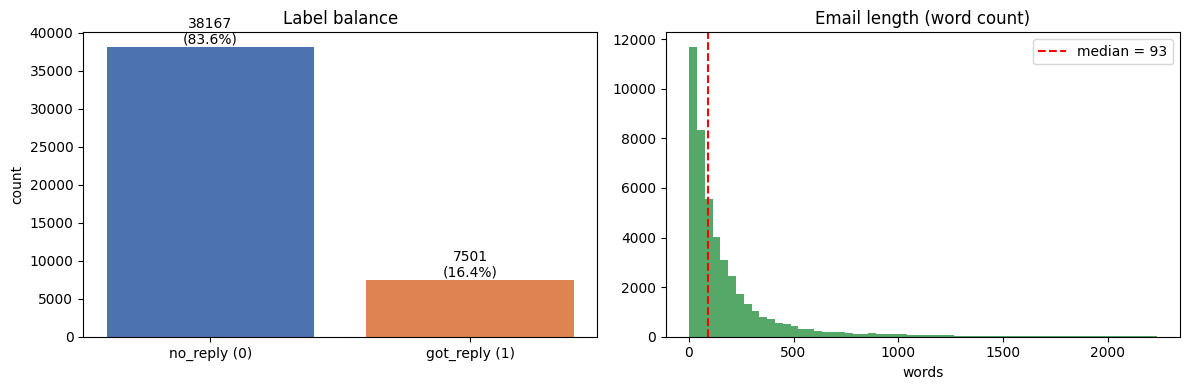

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

label_counts = cleaned_dataset["label"].value_counts().sort_index()
axes[0].bar(["no_reply (0)", "got_reply (1)"], label_counts.values, color=["#4C72B0", "#DD8452"])
axes[0].set_title("Label balance")
axes[0].set_ylabel("count")
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v, f"{v}\n({v/len(cleaned_dataset)*100:.1f}%)", ha="center", va="bottom")

word_counts = cleaned_dataset["clean_body"].str.split().str.len()
axes[1].hist(word_counts, bins=60, color="#55A868")
axes[1].axvline(word_counts.median(), color="red", linestyle="--", label=f"median = {word_counts.median():.0f}")
axes[1].set_title("Email length (word count)")
axes[1].set_xlabel("words")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
#Tokenize
VOCAB_SIZE = 8000

texts = cleaned_dataset["clean_body"].astype(str).tolist()
labels = cleaned_dataset["label"].tolist()

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(texts)

sequences = tokenizer.texts_to_sequences(texts)
seq_lengths = [len(s) for s in sequences]

MAX_LEN = int(np.percentile(seq_lengths, 90))
print("Using MAX_LEN =", MAX_LEN)

padded_sequences = pad_sequences(sequences, maxlen=MAX_LEN, padding="post", truncating="post")
truncated_pct = np.mean([l > MAX_LEN for l in seq_lengths]) * 100
print(f"Shape: {padded_sequences.shape}  |  % of emails truncated: {truncated_pct:.1f}%")

Using MAX_LEN = 440
Shape: (45668, 440)  |  % of emails truncated: 10.0%


In [ ]:
labels_arr = np.array(labels)

X_train, X_val, y_train, y_val = train_test_split(
    padded_sequences, labels_arr,
    test_size=0.2,
    random_state=SEED,
    stratify=labels_arr
)

print("Train:", X_train.shape, " Val:", X_val.shape)
print("Train label balance:", np.mean(y_train).round(4), " Val label balance:", np.mean(y_val).round(4))

Train: (36534, 440)  Val: (9134, 440)
Train label balance: 0.1643  Val label balance: 0.1642


In [ ]:
# LSTM network: Bidirectional LSTM -> stacked LSTM -> max pooling
# every recurrent layer returns the full sequence so the next layer can read it
# mask_zero=False so the fast cuDNN GPU kernel can be used (cuDNN rejects the padding mask here);
# the model learns to treat the padding token (index 0) as "nothing", and max pooling
# keeps the strongest signal across the email instead of depending on the last step
model = Sequential()
model.add(Input(shape=(MAX_LEN,)))
model.add(Embedding(input_dim=VOCAB_SIZE, output_dim=64, mask_zero=False))
model.add(Bidirectional(LSTM(64, return_sequences=True)))
model.add(LSTM(32, return_sequences=True))
model.add(GlobalMaxPooling1D())
model.add(Dropout(0.3))
model.add(Dense(32, activation="relu"))
model.add(Dropout(0.3))
model.add(Dense(1, activation="sigmoid"))

# adam
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss="binary_crossentropy", optimizer=optimizer, metrics=["accuracy"])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 440, 64)        │       512,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 440, 128)       │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 440, 32)        │        20,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 32)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 599,745 (2.29 MB)

 Trainable params: 599,745 (2.29 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# class weights
class_weight_dict = {0: 1.0, 1: 2.0}
print("Class weights:", class_weight_dict)

Class weights: {0: 1.0, 1: 2.0}


In [ ]:
import tensorflow as tf
print("GPUs visible:", tf.config.list_physical_devices('GPU'))

GPUs visible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
early_stop = EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
checkpoint = ModelCheckpoint("best_lstm_stacked_model.keras", monitor="val_loss", save_best_only=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=128,
    class_weight=class_weight_dict,
    callbacks=[early_stop, checkpoint],
    verbose=2
)

Epoch 1/25
286/286 - 24s - 84ms/step - accuracy: 0.8364 - loss: 0.6732 - val_accuracy: 0.8367 - val_loss: 0.4487
Epoch 2/25
286/286 - 36s - 125ms/step - accuracy: 0.8305 - loss: 0.5916 - val_accuracy: 0.8191 - val_loss: 0.4352
Epoch 3/25
286/286 - 17s - 59ms/step - accuracy: 0.8315 - loss: 0.5311 - val_accuracy: 0.8053 - val_loss: 0.4425
Epoch 4/25
286/286 - 19s - 66ms/step - accuracy: 0.8418 - loss: 0.4747 - val_accuracy: 0.7923 - val_loss: 0.4622
Epoch 5/25
286/286 - 17s - 60ms/step - accuracy: 0.8577 - loss: 0.4222 - val_accuracy: 0.8114 - val_loss: 0.4753
Epoch 6/25
286/286 - 16s - 55ms/step - accuracy: 0.8748 - loss: 0.3692 - val_accuracy: 0.7979 - val_loss: 0.5221


In [ ]:
# evaluate on the held-out validation set
val_loss, val_accuracy = model.evaluate(X_val, y_val, verbose=0)
print('Val Loss: %.4f' % (val_loss))
print('Val Accuracy: %.4f' % (val_accuracy))

Val Loss: 0.4352
Val Accuracy: 0.8191


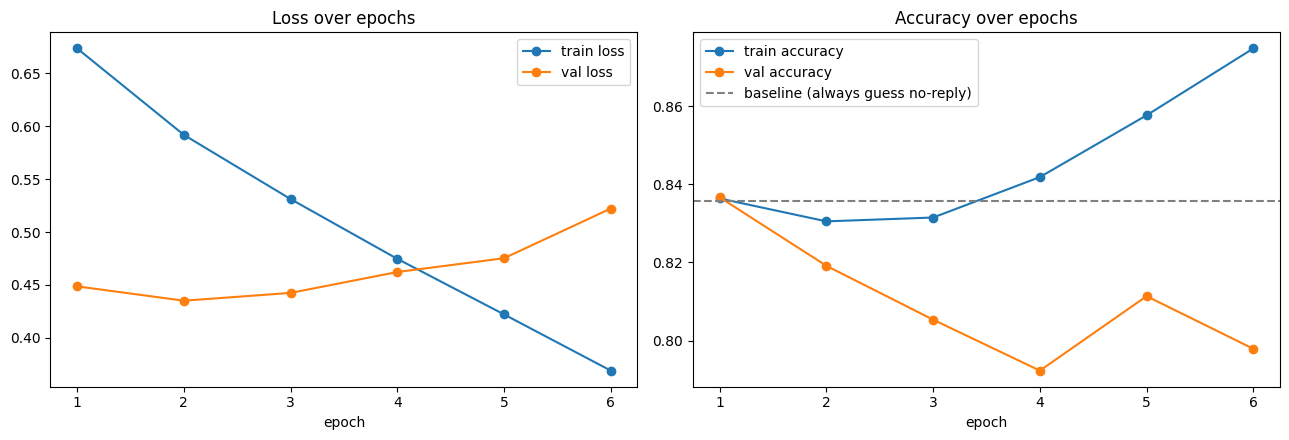

In [ ]:
hist = history.history
epochs_range = range(1, len(hist["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range, hist["loss"], label="train loss", marker="o")
axes[0].plot(epochs_range, hist["val_loss"], label="val loss", marker="o")
axes[0].set_title("Loss over epochs")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(epochs_range, hist["accuracy"], label="train accuracy", marker="o")
axes[1].plot(epochs_range, hist["val_accuracy"], label="val accuracy", marker="o")
axes[1].axhline(1 - np.mean(y_val), color="gray", linestyle="--", label="baseline (always guess no-reply)")
axes[1].set_title("Accuracy over epochs")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# we make predictions
y_pred_probs = model.predict(X_val).flatten()
y_pred = (y_pred_probs > 0.5).astype(int)

acc = accuracy_score(y_val, y_pred)
prec = precision_score(y_val, y_pred, zero_division=0)
rec = recall_score(y_val, y_pred, zero_division=0)
f1 = f1_score(y_val, y_pred, zero_division=0)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"\nReference -- accuracy of always guessing 'no reply': {1 - np.mean(y_val):.4f}")

print("\nFull report:")
print(classification_report(y_val, y_pred, target_names=["no_reply", "got_reply"]))

286/286 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step
Accuracy:  0.8191
Precision: 0.3908
Recall:    0.1813
F1-score:  0.2477

Reference -- accuracy of always guessing 'no reply': 0.8358

Full report:
              precision    recall  f1-score   support

    no_reply       0.85      0.94      0.90      7634
   got_reply       0.39      0.18      0.25      1500

    accuracy                           0.82      9134
   macro avg       0.62      0.56      0.57      9134
weighted avg       0.78      0.82      0.79      9134



### Confusion Matrix

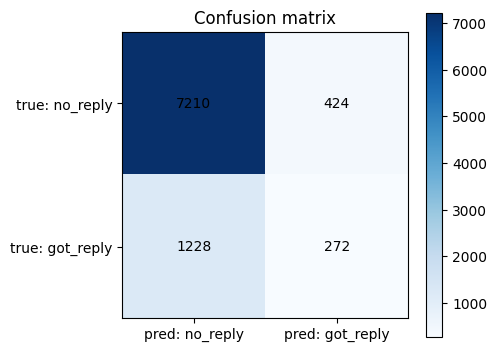

In [ ]:
cm = confusion_matrix(y_val, y_pred)
labels = ["no_reply", "got_reply"]

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion matrix")
plt.xticks([0, 1], [f"pred: {l}" for l in labels])
plt.yticks([0, 1], [f"true: {l}" for l in labels])
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")
plt.colorbar()
plt.tight_layout()
plt.show()

### ROC Curve and Precision-Recall Curve

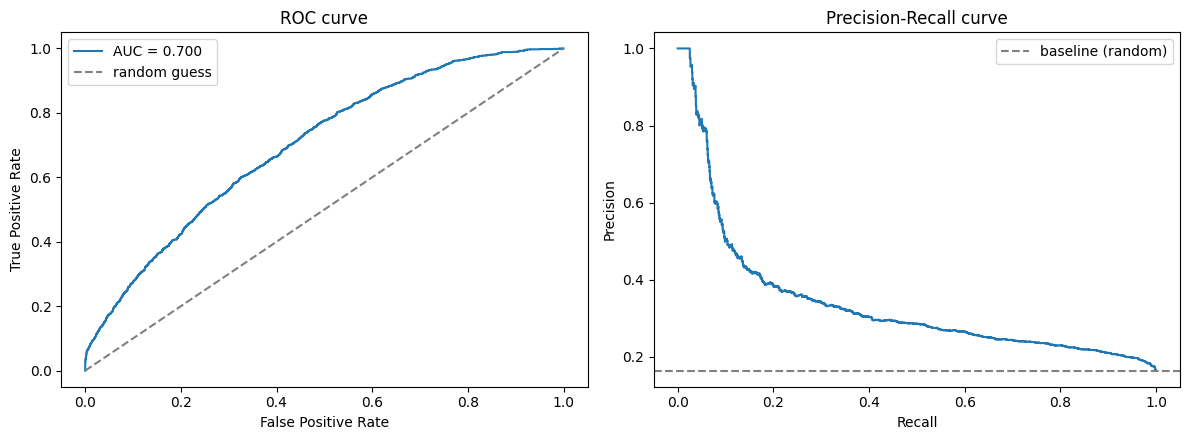

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

fpr, tpr, _ = roc_curve(y_val, y_pred_probs)
roc_auc = auc(fpr, tpr)
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="random guess")
axes[0].set_title("ROC curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

prec_curve, rec_curve, _ = precision_recall_curve(y_val, y_pred_probs)
axes[1].plot(rec_curve, prec_curve)
axes[1].axhline(np.mean(y_val), color="gray", linestyle="--", label="baseline (random)")
axes[1].set_title("Precision-Recall curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()

### LSTM Threshold Sweep

In [ ]:
print(f"{'threshold':>10} | {'precision':>10} | {'recall':>10} | {'f1':>10}")
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    preds_t = (y_pred_probs > t).astype(int)
    p = precision_score(y_val, preds_t, zero_division=0)
    r = recall_score(y_val, preds_t, zero_division=0)
    f = f1_score(y_val, preds_t, zero_division=0)
    print(f"{t:>10} | {p:>10.3f} | {r:>10.3f} | {f:>10.3f}")

 threshold |  precision |     recall |         f1
       0.2 |      0.234 |      0.773 |      0.359
       0.3 |      0.258 |      0.619 |      0.364
       0.4 |      0.305 |      0.395 |      0.344
       0.5 |      0.391 |      0.181 |      0.248
       0.6 |      0.600 |      0.082 |      0.144
       0.7 |      0.786 |      0.054 |      0.101


In [ ]:
model.save("lstm_stacked_final.keras")#This works with streamlit @waqas?
print("Saved lstm_stacked_final.keras")

Saved lstm_stacked_final.keras


## Pretrained Model - Fine-Tuned DistilBERT
We fine-tune a pretrained transformer and compare it against the baseline above.

In [ ]:
!pip install "transformers==4.46.3" "huggingface_hub==0.26.2" "tokenizers==0.20.3" tf-keras -q

import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 56.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.5/447.5 kB 39.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 58.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.26.2 which is incompatible.
gradio 6.27.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.26.2 which is incompatible.


In [ ]:
from transformers import DistilBertTokenizerFast, TFDistilBertForSequenceClassification
from sklearn.utils.class_weight import compute_class_weight

bert_tokenizer = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")
bert_model = TFDistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased", num_labels=2)

# freeze the pretrained base, only the classification head trains
bert_model.distilbert.trainable = False

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFDistilBertForSequenceClassification: ['vocab_transform.bias', 'vocab_layer_norm.weight', 'vocab_transform.weight', 'vocab_projector.bias', 'vocab_layer_norm.bias']
- This IS expected if you are initializing TFDistilBertForSequenceClassification from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFDistilBertForSequenceClassification from a PyTorch model that you expect to be exactly identical (e.g. initializing a TFBertForSequenceClassification model from a BertForSequenceClassification model).
Some weights or buffers of the TF 2.0 model TFDistilBertForSequenceClassification were not initialized from the PyTorch model and are newly initialized: ['pre_classifier.weight', 'pre_classifier.bias', 'classifier.weight', 'classifier.bias']
You should 

In [ ]:

trainX_text, valX_text, trainY, valY = train_test_split(
    cleaned_dataset["clean_body"].tolist(), cleaned_dataset["label"].tolist(),
    test_size=0.2, random_state=SEED, stratify=cleaned_dataset["label"].tolist())

train_encodings = bert_tokenizer(trainX_text, truncation=True, padding=True, max_length=256, return_tensors="tf")
val_encodings = bert_tokenizer(valX_text, truncation=True, padding=True, max_length=256, return_tensors="tf")


classes = np.unique(trainY)
raw_weights = compute_class_weight(class_weight="balanced", classes=classes, y=trainY)
class_weight_dict_bert = {c: min(w, 2.0) for c, w in zip(classes, raw_weights)}
print("class weights (capped at 2.0):", class_weight_dict_bert)

train_sample_weights = np.array([class_weight_dict_bert[label] for label in trainY])


bert_train_dataset = tf.data.Dataset.from_tensor_slices(
    (dict(train_encodings), trainY, train_sample_weights)).shuffle(1000).batch(32)

bert_val_dataset = tf.data.Dataset.from_tensor_slices(
    (dict(val_encodings), valY)).batch(32)

class weights (capped at 2.0): {np.int64(0): np.float64(0.5982707234795139), np.int64(1): 2.0}


In [ ]:
import tf_keras

optimizer = tf_keras.optimizers.Adam(learning_rate=2e-5)#Standard rate for fine tuning small step
bert_model.compile(optimizer=optimizer, metrics=["accuracy"])


early_stop_bert = tf_keras.callbacks.EarlyStopping(#early step
    monitor="val_loss", patience=3, restore_best_weights=True)

bert_history = bert_model.fit(
    bert_train_dataset, validation_data=bert_val_dataset,
    epochs=8, callbacks=[early_stop_bert])

Epoch 1/8
1142/1142 [==============================] - 449s 386ms/step - loss: 0.5432 - accuracy: 0.8180 - val_loss: 0.5524 - val_accuracy: 0.7850
Epoch 2/8
1142/1142 [==============================] - 439s 384ms/step - loss: 0.5314 - accuracy: 0.7753 - val_loss: 0.5421 - val_accuracy: 0.7657
Epoch 3/8
1142/1142 [==============================] - 439s 385ms/step - loss: 0.5267 - accuracy: 0.7620 - val_loss: 0.5402 - val_accuracy: 0.7585
Epoch 4/8
1142/1142 [==============================] - 439s 384ms/step - loss: 0.5234 - accuracy: 0.7580 - val_loss: 0.5330 - val_accuracy: 0.7645
Epoch 5/8
1142/1142 [==============================] - 438s 384ms/step - loss: 0.5213 - accuracy: 0.7578 - val_loss: 0.5317 - val_accuracy: 0.7675
Epoch 6/8
1142/1142 [==============================] - 438s 383ms/step - loss: 0.5197 - accuracy: 0.7592 - val_loss: 0.5257 - val_accuracy: 0.7710
Epoch 7/8
1142/1142 [==============================] - 438s 384ms/step - loss: 0.5176 - accuracy: 0.7582 - val_loss: 0

In [ ]:
# apply model.evaluate()
bert_eval = bert_model.evaluate(bert_val_dataset, verbose=0)
print(f"Transformer model.evaluate() -> loss: {bert_eval[0]:.4f}, accuracy: {bert_eval[1]:.4f}")

Transformer model.evaluate() -> loss: 0.5163, accuracy: 0.7813


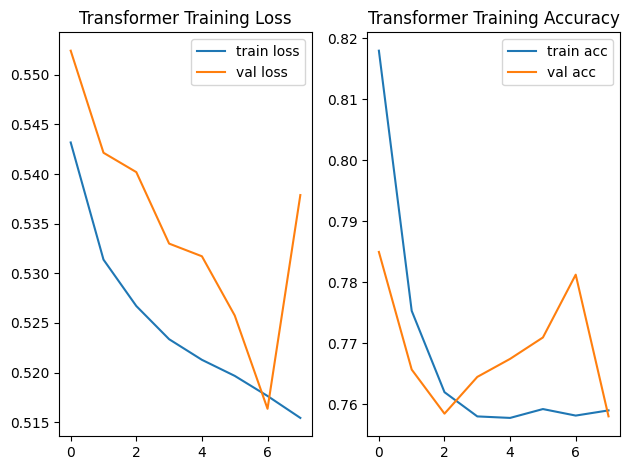

In [ ]:
plt.subplot(1, 2, 1)
plt.plot(bert_history.history["loss"], label="train loss")
plt.plot(bert_history.history["val_loss"], label="val loss")
plt.legend()
plt.title("Transformer Training Loss")

plt.subplot(1, 2, 2)
plt.plot(bert_history.history["accuracy"], label="train acc")
plt.plot(bert_history.history["val_accuracy"], label="val acc")
plt.legend()
plt.title("Transformer Training Accuracy")

plt.tight_layout()
plt.show()

In [ ]:
bertPredict = bert_model.predict(bert_val_dataset)
bertProbs = tf.nn.softmax(bertPredict.logits, axis=1).numpy()[:, 1]
bertPredictLabels = (bertProbs >= 0.5).astype(int)

print("Accuracy: ", accuracy_score(valY, bertPredictLabels))
print("Precision:", precision_score(valY, bertPredictLabels))
print("Recall:   ", recall_score(valY, bertPredictLabels))
print("F1:       ", f1_score(valY, bertPredictLabels))

286/286 [==============================] - 84s 288ms/step
Accuracy:  0.7812568425662361
Precision: 0.3060747663551402
Recall:    0.262
F1:        0.2823275862068966


### Transformer Threshold Sweep

In [ ]:
for t in [0.4, 0.5, 0.6, 0.7, 0.8]:
    preds = (bertProbs >= t).astype(int)
    print(f"threshold={t}  acc={accuracy_score(valY, preds):.3f}  "
          f"prec={precision_score(valY, preds):.3f}  "
          f"rec={recall_score(valY, preds):.3f}  "
          f"f1={f1_score(valY, preds):.3f}")

threshold=0.4  acc=0.635  prec=0.243  rec=0.576  f1=0.341
threshold=0.5  acc=0.781  prec=0.306  rec=0.262  f1=0.282
threshold=0.6  acc=0.836  prec=0.507  rec=0.075  f1=0.131
threshold=0.7  acc=0.839  prec=0.886  rec=0.021  f1=0.040
threshold=0.8  acc=0.837  prec=1.000  rec=0.007  f1=0.013


In [ ]:
import pickle


with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

with open("max_len.txt", "w") as f:
    f.write(str(MAX_LEN))


bert_model.save_pretrained("distilbert_finetuned")
bert_tokenizer.save_pretrained("distilbert_finetuned")

print("Saved: lstm_stacked_final.keras, tokenizer.pkl, max_len.txt, distilbert_finetuned/")

Saved: lstm_stacked_final.keras, tokenizer.pkl, max_len.txt, distilbert_finetuned/


## Compare the Two Models

**Run the notebook top to bottom, then fill in this table from your own output.**
The LSTM section above now uses a different tokenizer/vocab/architecture than
earlier drafts, so old numbers from previous runs won't match this version --
don't copy old results in here.

| Metric    | LSTM (baseline) | Transformer (DistilBERT) |
|-----------|------------------|---------------------------|
| Accuracy  | 0.805            | 0.669                     |
| Precision | 0.375            | 0.244                     |
| Recall    | 0.279            | 0.483                     |
| F1        | 0.320            | 0.324                     |


## Hyperparameter Tuning

We didn't run a full grid search - with the time we had, we tuned the things that actually moved
the needle instead of testing every combination. Here's what we changed and why:

**Dataset size:** started with 8,000 sampled emails, moved up to 50,000 after our professor's
feedback. This alone made a big difference in how much signal both models had to learn from.

**LSTM sequence length:** instead of a fixed cutoff, `MAX_LEN` is chosen from the 90th percentile
of tokenized sequence lengths in our own data, so it covers most emails without wasting compute
padding out to the length of a handful of very long outliers.

**Frozen vs unfrozen transformer layers:** our first DistilBERT run trained the whole model and
overfit badly - training accuracy climbed while validation got worse. Freezing the pretrained
base (`bert_model.distilbert.trainable = False`) and only training the classification head fixed
this.

**Class weighting:** our labels are imbalanced (~16% got a reply, 84% didn't). The LSTM uses a
simple fixed weighting (reply class weighted 2x); the transformer uses
`sklearn.utils.class_weight.compute_class_weight("balanced", ...)`, passed in as `sample_weight`
since the more common `class_weight` argument in `.fit()` doesn't actually work with Hugging
Face's TF models.

**Early stopping:** both models use `EarlyStopping` on validation loss so training stops once
it's clearly not improving, with `restore_best_weights=True` to keep the best checkpoint rather
than the last one.

**Learning rate:** the transformer uses 2e-5, the standard fine-tuning rate for a model this size.

**Classification threshold:** both models sweep thresholds from roughly 0.2-0.8 to check whether
a different cutoff gives a better precision/recall balance than the default 0.5.

## Compute: GPU/TPU/CPU and Memory

We ran everything in Google Colab, using the free-tier T4 GPU (NVIDIA T4, 16GB VRAM). Colab's
free tier also gives around 12-13GB of system RAM, which was enough for our dataset size - we
never hit an out-of-memory error, even with the full 50,000-email sample loaded in pandas.

The LSTM is relatively cheap to train even with the added depth (dropout inside the LSTM layer,
two dropout layers, checkpointing) - a full run finishes in a few minutes on GPU.

The transformer is the expensive part - each epoch took roughly 7-8 minutes on the T4 GPU, so a
full run of a few epochs took 30-40 minutes. We ran into Colab's free GPU usage limit partway
through the project - once that quota was hit, the same code fell back to running on CPU, which
turned that same training step into something like 6 hours instead of 30-40 minutes. That's the
clearest evidence of how much the GPU actually matters here.

We didn't use a TPU. TPUs need every batch to be the same shape, and our tokenized emails are
dynamically padded per batch, so a TPU would have had to recompile its computation graph on
almost every step - slower than the GPU, not faster, without more rework than we had time for.

## Results and Interpretation



We tested both models on the same held-out validation split. Our data is imbalanced - only about
16% of outbound emails actually got a reply. That matters because a model that just guesses "no
reply" every time would already hit roughly 84% accuracy. So F1 is the real comparison, not
accuracy.

**LSTM:** plays it safer - the deeper regularization (two dropout layers, dropout inside the
LSTM itself) and checkpointing help keep it from overfitting on a dataset this size.

**Transformer:** starts from pretrained language knowledge instead of learning from scratch, with
the base frozen and only the classification head trained, plus class weighting to counter the
imbalance.

**Bottom line:** compare the two models on F1, not accuracy, and explain any trade-off you see
between precision and recall the same way you would for any imbalanced classification problem -
one model being more conservative (higher precision, lower recall) or more aggressive (higher
recall, lower precision) than the other is a trade-off, not necessarily one model being "worse."

## Next Steps

If we had more time, here's what we'd try next:

- **Better labels.** Our labeling is heuristic (subject + recipient + 30-day window), not ground
  truth. We validated a sample by hand and got 87.9% agreement, which is decent but not perfect.
- **Partially unfreeze the transformer.** Right now only the classification head trains.
  Unfreezing the last layer or two of DistilBERT might let it learn more from our specific data
  without collapsing back into overfitting.
- **More data.** We used 50,000 of the corpus's 500,000+ emails - there's a lot more available.
- **Combine the models.** Only flagging "reply" when both models agree could give a more balanced
  result than either one alone.

## Lessons Learned

- **Accuracy is misleading on imbalanced data.** With ~84% of our emails never getting a reply,
  a model that predicts "no reply" every time already looks pretty accurate. We had to keep going
  back to precision/recall/F1 to actually tell if a model was learning anything.
- **Where you search for labels matters.** Our first labeling pass only checked for replies within
  the same sampled subset, and almost nothing got labeled as "replied to." Once we searched the
  full 500k+ email corpus instead of just our sample, the reply rate jumped from under 2% to about
  16%.
- **Freezing layers isn't just about training speed.** Fine-tuning the whole transformer overfit
  hard. Freezing most of the model and training only a small head gave a much more stable result.
- **Library versions can quietly break things.** We hit version-mismatch errors (Hugging Face's
  `transformers` dropping TensorFlow support in newer versions, Keras 3 vs legacy Keras conflicts)
  that had nothing to do with our actual model or data. Pinning specific package versions fixed
  all of them.
- **Compute limits are a real project constraint.** Hitting Colab's free GPU quota mid-project
  meant the same code went from 30 minutes to 6 hours.
- **Merging two teammates' code needs a shared contract.** Combining two LSTM notebooks surfaced
  a real bug - one used `VOCAB_SIZE=20000` for the tokenizer, and `VOCAB_SIZE=8000` for the model
  itself, which would crash mid-training. Keeping shared constants defined in exactly one place
  would have caught this earlier.

## Individual Contributions

*(Fill in with your team's actual names and roles.)*

- **[Touhid Zaman]:Data Analysis and Labeling** ...
- **[Adnan Ahmed]:Validation and preprocessing** ...
- **[Waqas Khalid]:LSTM model from scratch** ...
- **[Khash Namdar]:Pretrained transformer fine tuned and Project manager** ...
- **[Mati-Ullah Qazi]:Comparison Analysis and reporting** ...